In [ ]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Create login activity training dataset

data = pd.DataFrame({
    'failed_logins': [0, 1, 0, 2, 1, 6, 8, 5, 7, 9,
                      2, 0, 6, 1, 8, 3],
    'login_hour': [10, 14, 9, 16, 11, 2, 3, 23, 1, 0,
                   12, 15, 4, 13, 2, 22],
    'new_device': [0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
                   0, 0, 1, 0, 1, 1],
    'download_mb': [40, 80, 60, 100, 90, 150, 600, 400,
                    700, 800, 70, 50, 550, 100, 650, 450],
    'label': ['Normal', 'Normal', 'Normal', 'Normal',
              'Normal', 'Suspicious', 'Suspicious',
              'Suspicious', 'Suspicious', 'Suspicious',
              'Normal', 'Normal', 'Suspicious', 'Normal',
              'Suspicious', 'Suspicious']
})

# Separate features and target
features = ['failed_logins', 'login_hour',
            'new_device', 'download_mb']

X = data[features]
y = data['label']

# Train Decision Tree model
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

print("Dataset created successfully!")
print("Decision Tree model trained successfully!")

# Display training dataset
display(data)


Dataset created successfully!
Decision Tree model trained successfully!


,failed_logins,login_hour,new_device,download_mb,label
0,0,10,0,40,Normal
1,1,14,0,80,Normal
2,0,9,0,60,Normal
3,2,16,0,100,Normal
4,1,11,1,90,Normal
5,6,2,1,150,Suspicious
6,8,3,1,600,Suspicious
7,5,23,1,400,Suspicious
8,7,1,1,700,Suspicious
9,9,0,1,800,Suspicious


In [3]:

# Create five sanitized login activity records

samples = pd.DataFrame([
    {'account_id': 'ACC-1001', 'ip_address': '192.168.10.24',
     'failed_logins': 0, 'login_hour': 10,
     'new_device': 0, 'download_mb': 40},

    {'account_id': 'ACC-1002', 'ip_address': '10.0.4.18',
     'failed_logins': 7, 'login_hour': 2,
     'new_device': 1, 'download_mb': 150},

    {'account_id': 'ACC-1003', 'ip_address': '172.16.8.90',
     'failed_logins': 1, 'login_hour': 15,
     'new_device': 0, 'download_mb': 720},

    {'account_id': 'ACC-1004', 'ip_address': '192.168.20.11',
     'failed_logins': 4, 'login_hour': 23,
     'new_device': 1, 'download_mb': 400},

    {'account_id': 'ACC-1005', 'ip_address': '10.1.1.9',
     'failed_logins': 2, 'login_hour': 9,
     'new_device': 0, 'download_mb': 80}
])

# Generate predictions
samples['prediction'] = model.predict(samples[features])

# Calculate prediction confidence
samples['confidence'] = model.predict_proba(
    samples[features]
).max(axis=1).round(3)

# Display results
display(samples)


,account_id,ip_address,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-1001,192.168.10.24,0,10,0,40,Normal,1.0
1,ACC-1002,10.0.4.18,7,2,1,150,Suspicious,1.0
2,ACC-1003,172.16.8.90,1,15,0,720,Normal,1.0
3,ACC-1004,192.168.20.11,4,23,1,400,Suspicious,1.0
4,ACC-1005,10.1.1.9,2,9,0,80,Normal,1.0


In [4]:

# Find the record with the lowest confidence

lowest_confidence = samples.loc[
    samples['confidence'].idxmin()
]

print("Lowest Confidence Record:")
display(lowest_confidence.to_frame())

print("\nConfidence is not certainty because a model")
print("can make incorrect predictions even with high confidence.")


Lowest Confidence Record:


,0
account_id,ACC-1001
ip_address,192.168.10.24
failed_logins,0
login_hour,10
new_device,0
download_mb,40
prediction,Normal
confidence,1.0



Confidence is not certainty because a model
can make incorrect predictions even with high confidence.


Feature Importance Table:


,feature,importance
0,failed_logins,1.0
1,login_hour,0.0
2,new_device,0.0
3,download_mb,0.0


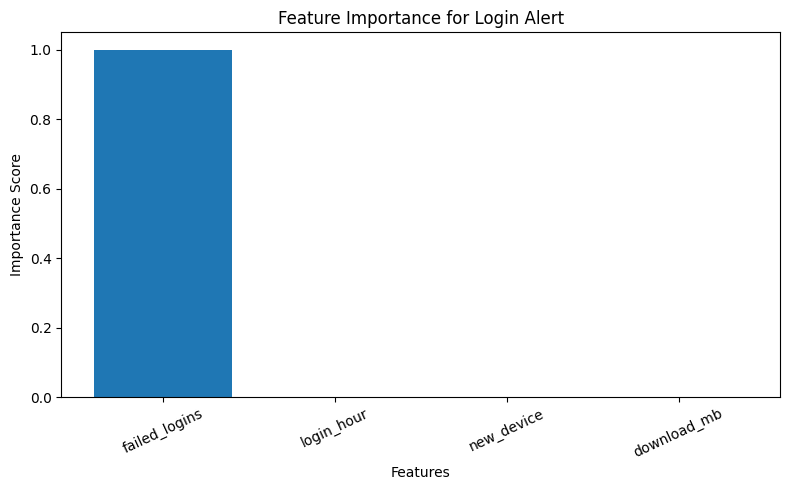

In [5]:

# Calculate feature importance

importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

# Display sorted feature importance
print("Feature Importance Table:")
display(importance)

# Plot feature importance
plt.figure(figsize=(8, 5))

plt.bar(importance['feature'], importance['importance'])

plt.title('Feature Importance for Login Alert')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()


In [6]:

# Select the fifth baseline record
baseline = samples.iloc[[4]].copy()

# Create a modified copy
changed = baseline.copy()

# Change only failed_logins from 2 to 8
changed['failed_logins'] = 8

# Baseline prediction and confidence
baseline_prediction = model.predict(
    baseline[features]
)[0]

baseline_confidence = model.predict_proba(
    baseline[features]
).max()

# Modified prediction and confidence
changed_prediction = model.predict(
    changed[features]
)[0]

changed_confidence = model.predict_proba(
    changed[features]
).max()

# Display comparison
comparison = pd.DataFrame({
    'Version': ['Baseline', 'Modified'],
    'Failed Logins': [
        baseline['failed_logins'].iloc[0],
        changed['failed_logins'].iloc[0]
    ],
    'Prediction': [
        baseline_prediction,
        changed_prediction
    ],
    'Confidence': [
        round(baseline_confidence, 3),
        round(changed_confidence, 3)
    ]
})

display(comparison)


,Version,Failed Logins,Prediction,Confidence
0,Baseline,2,Normal,1.0
1,Modified,8,Suspicious,1.0


In [7]:

print("Sensitivity Test Interpretation:")
print("1. The baseline record had 2 failed login attempts.")
print("2. The modified record had 8 failed login attempts.")
print("3. All other input features remained unchanged.")

if baseline_prediction != changed_prediction:
    print("4. The model prediction changed after modifying the input.")
else:
    print("4. The model prediction remained the same after modifying the input.")

print("5. This test shows how the model responds to changes")
print("   in failed login attempts.")


Sensitivity Test Interpretation:
1. The baseline record had 2 failed login attempts.
2. The modified record had 8 failed login attempts.
3. All other input features remained unchanged.
4. The model prediction changed after modifying the input.
5. This test shows how the model responds to changes
   in failed login attempts.


In [8]:

# Function to mask IP address

def mask_ip(ip):
    parts = str(ip).split('.')

    if len(parts) == 4:
        return f'{parts[0]}.{parts[1]}.xxx.xxx'

    return '<MASKED_IP>'


# Function to mask account ID

def mask_account(account_id):
    text = str(account_id)

    return text[:4] + '***' + text[-2:]


# Apply masking functions
samples['masked_ip'] = samples['ip_address'].apply(mask_ip)

samples['masked_account'] = samples['account_id'].apply(
    mask_account
)

# Display only masked identifiers
print("Privacy Protected Login Records:")

display(samples[[
    'masked_account',
    'masked_ip',
    'prediction',
    'confidence'
]])


Privacy Protected Login Records:


,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,1.0
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.0
2,ACC-***03,172.16.xxx.xxx,Normal,1.0
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.0
4,ACC-***05,10.1.xxx.xxx,Normal,1.0


In [9]:

# Four privacy and responsible-use rules

privacy_rules = [
    'Mask identifiers before display or export.',
    'Use sanitized data in classroom notebooks.',
    'Restrict access to unmasked records.',
    'Require human review for high-risk action.'
]

print("Privacy and Responsible-Use Rules:\n")

for rule in privacy_rules:
    print("-", rule)


Privacy and Responsible-Use Rules:

- Mask identifiers before display or export.
- Use sanitized data in classroom notebooks.
- Restrict access to unmasked records.
- Require human review for high-risk action.


In [10]:

# Function to identify reasons for suspicious activity

def numeric_reason(row):
    reasons = []

    if row['failed_logins'] >= 5:
        reasons.append('many failed logins')

    if row['new_device'] == 1:
        reasons.append('new device')

    if row['login_hour'] < 6 or row['login_hour'] > 22:
        reasons.append('unusual login time')

    if row['download_mb'] >= 500:
        reasons.append('large data download')

    return ', '.join(reasons) if reasons else 'no strong warning'


# Function to generate responsible alerts

def make_alert(row):
    reason = numeric_reason(row)

    if row['prediction'] == 'Suspicious':
        severity = 'High'
        action = 'Verify, contain if required, and report.'

    elif row['confidence'] < 0.70:
        severity = 'Medium'
        action = 'Send for analyst review before action.'

    else:
        severity = 'Low'
        action = 'Continue normal monitoring.'

    human_review = (
        'Yes'
        if severity in ['High', 'Medium']
        else 'No'
    )

    return severity, reason, action, human_review


# Generate alerts for all five records

alerts = samples.apply(make_alert, axis=1)

samples[[
    'severity',
    'reason',
    'recommended_action',
    'human_review'
]] = pd.DataFrame(alerts.tolist(), index=samples.index)


# Display final responsible alert table

print("FINAL RESPONSIBLE SECURITY ALERTS")

display(samples[[
    'masked_account',
    'prediction',
    'confidence',
    'severity',
    'reason',
    'recommended_action',
    'human_review'
]])


FINAL RESPONSIBLE SECURITY ALERTS


,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.0,High,"many failed logins, new device, unusual login ...","Verify, contain if required, and report.",Yes
2,ACC-***03,Normal,1.0,Low,large data download,Continue normal monitoring.,No
3,ACC-***04,Suspicious,1.0,High,"new device, unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No


In [11]:

# Count alerts by severity

print("SECURITY ALERT SUMMARY")

print("\nHigh Severity:",
      (samples['severity'] == 'High').sum())

print("Medium Severity:",
      (samples['severity'] == 'Medium').sum())

print("Low Severity:",
      (samples['severity'] == 'Low').sum())

print("\nHuman Review Required:",
      (samples['human_review'] == 'Yes').sum())

print("\nTotal Records:", len(samples))


SECURITY ALERT SUMMARY

High Severity: 2
Medium Severity: 0
Low Severity: 3

Human Review Required: 2

Total Records: 5


## Conclusion

In this experiment, we developed an AI-based login threat detection system using a Decision Tree classifier. We generated predictions with confidence scores, analyzed feature importance, and performed a controlled sensitivity test by changing failed login attempts. We also applied privacy masking to account IDs and IP addresses and generated responsible security alerts with severity, reasons, recommended actions, and human-review status.

This experiment demonstrates how Explainable and Privacy-Aware AI can help improve cybersecurity monitoring while maintaining privacy and human oversight.